# 🗺️ PathSnap — Phase 2: Bayesian Optimization + HMM/Viterbi + Visualizations

**Course:** UE24CS352A — Machine Learning | PES University  
**Covers:** Phase 4 (Bayesian Opt) → Phase 5 (HMM + Viterbi) → Phase 6 (Folium Maps)

---
| Section | Phase | Description |
|---|---|---|
| 1 | Setup | Imports, paths, load model + features |
| 2 | Phase 4 | Bayesian Hyperparameter Optimization (Optuna, 50 trials) |
| 3 | Phase 5 | HMM + Viterbi Route Reconstruction (Before vs After) |
| 4 | Phase 6 | Folium Interactive Maps for all student-test trips |

## Section 1 — Setup & Imports

In [5]:
import os, sys, time, json, warnings
warnings.filterwarnings('ignore')
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 110

from IPython.display import display, HTML, IFrame
import networkx as nx
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score
import folium
from folium import FeatureGroup, LayerControl

from src.data.loader import load_trip, get_available_trip_ids
from src.features.spatial import LocalMetricProjector, compute_angle_difference
from src.features.alignment import align_route_to_observations
from src.features.candidates import RoadNetworkIndex
from src.features.build_features import FEATURE_COLUMNS, extract_features_for_trip
from src.models.metrics import compute_observation_metrics

print('✅ All imports successful')

✅ All imports successful


In [6]:
# ── Paths ─────────────────────────────────────────────────────
TRAIN_FEATURES   = '../artifacts/results/train_features.csv.gz'
TEST_FEATURES    = '../artifacts/results/student_test_features.csv.gz'
MODEL_UNTUNED    = '../artifacts/models/HistGradientBoosting.joblib'
MODEL_TUNED      = '../artifacts/models/HistGradientBoosting_tuned.joblib'
BAYES_OUT        = '../artifacts/bayesian_opt'
MAPS_OUT         = '../artifacts/plots/folium_maps'
RESULTS_OUT      = '../artifacts/results'
EVAL_PARTITION   = '../Student folder/student_test'

os.makedirs(BAYES_OUT, exist_ok=True)
os.makedirs(MAPS_OUT,  exist_ok=True)
os.makedirs(RESULTS_OUT, exist_ok=True)

# ── Load pre-built features ────────────────────────────────────
print('Loading feature tables...')
train_df = pd.read_csv(TRAIN_FEATURES)
test_df  = pd.read_csv(TEST_FEATURES)

X_train       = train_df[FEATURE_COLUMNS].values
y_train       = train_df['target'].values
groups_train  = train_df['trip_id'].values
X_test        = test_df[FEATURE_COLUMNS].values
y_test        = test_df['target'].values

# ── Load untuned baseline model ────────────────────────────────
untuned_model = joblib.load(MODEL_UNTUNED)
print(f'Train: {X_train.shape[0]:,} rows from {train_df["trip_id"].nunique()} trips')
print(f'Test:  {X_test.shape[0]:,} rows from {test_df["trip_id"].nunique()} trips')
print(f'Loaded untuned model: {MODEL_UNTUNED}')

Loading feature tables...
Train: 1,667,336 rows from 80 trips
Test:  153,280 rows from 10 trips
Loaded untuned model: ../artifacts/models/HistGradientBoosting.joblib


---
## Section 2 — Phase 4: Bayesian Hyperparameter Optimization (Optuna)
Tune `HistGradientBoostingClassifier` using **TPE sampler** with 5-fold GroupKFold, maximising Macro F1.

In [7]:
# ── Untuned baseline on student-test ──────────────────────────
untuned_probs   = untuned_model.predict_proba(X_test)[:, 1]
untuned_metrics = compute_observation_metrics(test_df, untuned_probs)

print('═'*55)
print('UNTUNED HistGradientBoosting — Student-Test Results')
print('═'*55)
for k, v in untuned_metrics.items():
    print(f'  {k:<30}: {v:.4f}')

═══════════════════════════════════════════════════════
UNTUNED HistGradientBoosting — Student-Test Results
═══════════════════════════════════════════════════════
  obs_top1_accuracy             : 0.8187
  cand_macro_f1                 : 0.8495
  cand_precision                : 0.6143
  cand_recall                   : 0.9519
  cand_log_loss                 : 0.1926
  route_continuity              : 0.0000


In [8]:
N_TRIALS   = 50
N_CV_FOLDS = 5

def objective(trial):
    params = {
        'learning_rate':     trial.suggest_float('learning_rate',     0.01, 0.3,  log=True),
        'max_iter':          trial.suggest_int(  'max_iter',          50,   300),
        'max_leaf_nodes':    trial.suggest_int(  'max_leaf_nodes',    15,   127),
        'max_depth':         trial.suggest_int(  'max_depth',         3,    12),
        'min_samples_leaf':  trial.suggest_int(  'min_samples_leaf',  5,    50),
        'l2_regularization': trial.suggest_float('l2_regularization', 1e-4, 10.0, log=True),
        'max_bins':          trial.suggest_int(  'max_bins',          64,   255),
    }
    clf = HistGradientBoostingClassifier(**params, random_state=42,
                                         class_weight='balanced', early_stopping=False)
    gkf = GroupKFold(n_splits=N_CV_FOLDS)
    fold_f1s = []
    for train_idx, val_idx in gkf.split(X_train, y_train, groups_train):
        X_tr, y_tr = X_train[train_idx], y_train[train_idx]
        X_va, y_va = X_train[val_idx],   y_train[val_idx]
        if len(X_tr) > 300_000:
            rng = np.random.default_rng(42)
            idx = rng.choice(len(X_tr), 300_000, replace=False)
            X_tr, y_tr = X_tr[idx], y_tr[idx]
        clf.fit(X_tr, y_tr)
        y_pred = (clf.predict_proba(X_va)[:, 1] >= 0.5).astype(int)
        fold_f1s.append(f1_score(y_va, y_pred, average='macro', zero_division=0))
    return float(np.mean(fold_f1s))

db_path = os.path.join(BAYES_OUT, 'optuna_study.db')
study = optuna.create_study(
    study_name='pathsnap_hgb_tuning',
    direction='maximize',
    storage=f'sqlite:///{db_path}',
    load_if_exists=True,
    sampler=optuna.samplers.TPESampler(seed=42),
)
n_existing = len(study.trials)
n_needed   = max(0, N_TRIALS - n_existing)
print(f'Running {n_needed} new trials ({n_existing} already in DB)...')

t0 = time.time()
study.optimize(objective, n_trials=n_needed, show_progress_bar=True, n_jobs=1)
print(f'\n✅ Optimization done in {time.time()-t0:.1f}s')

best = study.best_trial
print(f'\nBest Trial #{best.number} — CV Macro F1 = {best.value:.4f}')
for k, v in best.params.items():
    print(f'  {k}: {v}')

with open(os.path.join(BAYES_OUT, 'best_params.json'), 'w') as f:
    json.dump({'best_cv_macro_f1': best.value, 'params': best.params}, f, indent=2)

Running 26 new trials (24 already in DB)...


Best trial: 44. Best value: 0.846966: 100%|██████████| 26/26 [09:16<00:00, 21.40s/it]


✅ Optimization done in 556.5s

Best Trial #44 — CV Macro F1 = 0.8470
  learning_rate: 0.2401859211829731
  max_iter: 264
  max_leaf_nodes: 109
  max_depth: 9
  min_samples_leaf: 10
  l2_regularization: 1.4327243580481313
  max_bins: 147


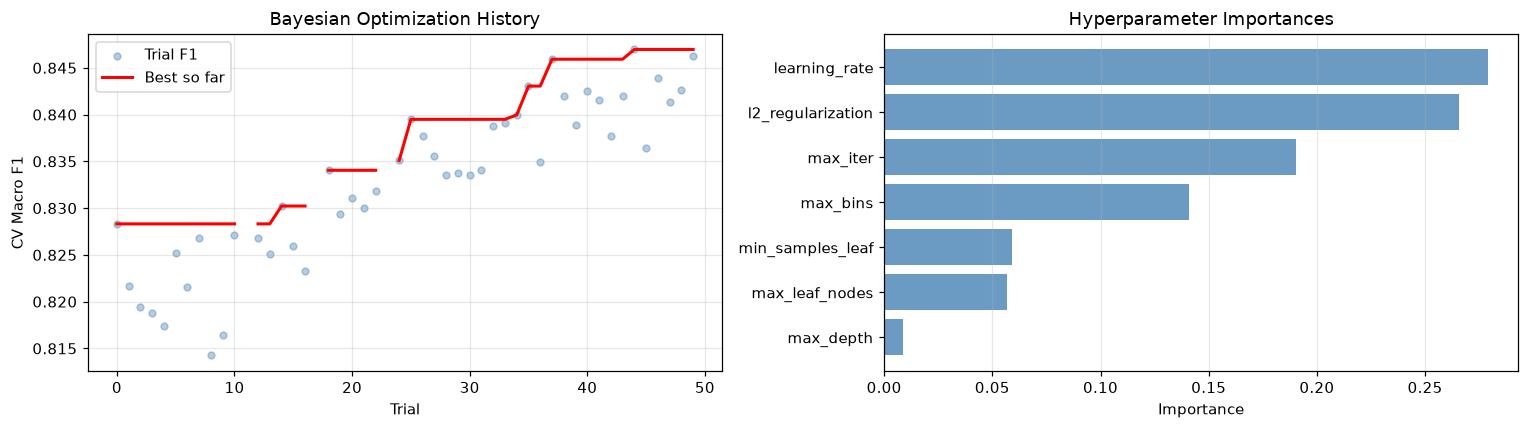

Saved 50 trial records


In [9]:
# ── Save trial history ─────────────────────────────────────────
trials_df = study.trials_dataframe()
trials_df.to_csv(os.path.join(BAYES_OUT, 'trials_history.csv'), index=False)

# ── Optimization history plot ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

ax = axes[0]
vals = trials_df['value'].values
best_so_far = pd.Series(vals).cummax().values
ax.scatter(trials_df['number'], vals, alpha=0.4, s=20, label='Trial F1', color='steelblue')
ax.plot(trials_df['number'], best_so_far, color='red', linewidth=2, label='Best so far')
ax.set_xlabel('Trial'); ax.set_ylabel('CV Macro F1')
ax.set_title('Bayesian Optimization History')
ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
try:
    importance = optuna.importance.get_param_importances(study)
    names = list(importance.keys())
    imps  = list(importance.values())
    ax.barh(names[::-1], imps[::-1], color='steelblue', alpha=0.8)
    ax.set_xlabel('Importance'); ax.set_title('Hyperparameter Importances')
    ax.grid(axis='x', alpha=0.3)
except Exception as e:
    ax.text(0.5, 0.5, str(e), ha='center', va='center')

plt.tight_layout()
fig.savefig(os.path.join(BAYES_OUT, 'optimization_plots.png'), dpi=120, bbox_inches='tight')
plt.show()
print(f'Saved {len(trials_df)} trial records')

In [10]:
# ── Refit tuned model on ALL training data ─────────────────────
print('Refitting tuned model on all training data...')
tuned_model = HistGradientBoostingClassifier(
    **best.params, random_state=42, class_weight='balanced', early_stopping=False
)
t_fit = time.time()
tuned_model.fit(X_train, y_train)
print(f'Fit time: {time.time()-t_fit:.1f}s')

joblib.dump(tuned_model, MODEL_TUNED)
print(f'Saved tuned model → {MODEL_TUNED}')

# ── Evaluate tuned model ───────────────────────────────────────
tuned_probs   = tuned_model.predict_proba(X_test)[:, 1]
tuned_metrics = compute_observation_metrics(test_df, tuned_probs)

comparison = pd.DataFrame([
    {'Config': 'Untuned (default)', **untuned_metrics},
    {'Config': f'Tuned (Optuna {N_TRIALS} trials)', **tuned_metrics},
])

comp_path = os.path.join(BAYES_OUT, 'tuned_vs_untuned.csv')
comparison.to_csv(comp_path, index=False)

print('\n━━━ Tuned vs Untuned Comparison ━━━')
display(comparison.style
    .highlight_max(axis=0, subset=[c for c in comparison.columns if c != 'Config' and 'loss' not in c], color='#c8f7c5')
    .highlight_min(axis=0, subset=[c for c in comparison.columns if 'loss' in c], color='#c8f7c5')
    .format({c: '{:.4f}' for c in comparison.columns if c != 'Config'})
    .set_caption('Green = better value')
)

Refitting tuned model on all training data...
Fit time: 10.9s
Saved tuned model → ../artifacts/models/HistGradientBoosting_tuned.joblib

━━━ Tuned vs Untuned Comparison ━━━


,Config,obs_top1_accuracy,cand_macro_f1,cand_precision,cand_recall,cand_log_loss,route_continuity
0,Untuned (default),0.8187,0.8495,0.6143,0.9519,0.1926,0.0000
1,Tuned (Optuna 50 trials),0.8196,0.8566,0.6341,0.9403,0.1768,0.0000


---
## Section 3 — Phase 5: HMM + Viterbi Route Reconstruction
Build the road graph, compute emission/transition log-probs, run Viterbi DP in log-space, compare **Before vs After HMM**.

In [11]:
# ── HMM utility functions ──────────────────────────────────────

EPS        = 1e-9
SIGMA_Z    = 25.0   # GPS noise std dev (m)
ALPHA      = 0.75   # weight: classifier vs Gaussian emission
BETA_TRANS = 30.0   # transition scale (m)
DROPOUT_S  = 5.0    # GPS dropout threshold (s)


def gaussian_log_emission(perp_dist, sigma_z=SIGMA_Z):
    return -0.5 * (perp_dist / sigma_z) ** 2


def emission_log_probs(clf_probs, perp_dists, sigma_z=SIGMA_Z, alpha=ALPHA):
    """Blend classifier probability and Gaussian distance model."""
    p = np.clip(clf_probs, EPS, 1.0)
    p = p / (p.sum() + EPS)
    log_clf   = np.log(p + EPS)
    log_gauss = np.array([gaussian_log_emission(d, sigma_z) for d in perp_dists])
    return alpha * log_clf + (1 - alpha) * log_gauss


def build_road_graph(trip, projector):
    """Build a NetworkX directed weighted graph for the trip's road network."""
    node_pts = projector.forward(trip.nodes['lon'].values, trip.nodes['lat'].values)
    G = nx.DiGraph()
    for arc_id, (u, v) in enumerate(zip(trip.arcs['u'].values, trip.arcs['v'].values)):
        length = float(np.linalg.norm(node_pts[v] - node_pts[u]))
        G.add_edge(u, v, weight=length, arc_id=arc_id)
    return G, node_pts


def transition_log_prob(G, ai, aj, arc_v_node, arc_u_node, gps_disp, beta, eps=EPS):
    """log P(to_arc | from_arc) based on network vs GPS displacement."""
    if ai == aj or arc_v_node == arc_u_node:
        return 0.0
    try:
        d_net = nx.shortest_path_length(G, arc_v_node, arc_u_node, weight='weight')
        return -abs(d_net - gps_disp) / beta
    except nx.NetworkXNoPath:
        return np.log(eps)


def route_continuity(arc_seq, arcs_df):
    if len(arc_seq) < 2:
        return 1.0
    u = arcs_df['u'].values
    v = arcs_df['v'].values
    same      = arc_seq[:-1] == arc_seq[1:]
    connected = v[arc_seq[:-1]] == u[arc_seq[1:]]
    return float(np.mean(same | connected))


print('✅ HMM utilities defined')

✅ HMM utilities defined


In [12]:
def viterbi_decode_trip(trip, model, k_cand=8):
    """Full HMM + Viterbi pipeline for a single trip."""
    center_lon = float(trip.track['lon'].mean())
    center_lat = float(trip.track['lat'].mean())
    projector  = LocalMetricProjector(center_lon, center_lat)

    pts        = projector.forward(trip.track['lon'].values, trip.track['lat'].values)
    n_pts      = len(pts)
    timestamps = trip.track['t'].values

    dx = np.diff(pts[:, 0], prepend=pts[0, 0])
    dy = np.diff(pts[:, 1], prepend=pts[0, 1])
    dt = np.diff(timestamps, prepend=timestamps[0] - 1.0)
    dt = np.where(dt <= 0, 1.0, dt)
    if n_pts > 1:
        dx[0] = pts[1, 0] - pts[0, 0]; dy[0] = pts[1, 1] - pts[0, 1]
        dt[0] = max(timestamps[1] - timestamps[0], 1.0)
    gps_headings = np.arctan2(dy, dx)
    speeds       = np.sqrt(dx**2 + dy**2) / dt

    road_index = RoadNetworkIndex(trip, projector)
    G, node_pts = build_road_graph(trip, projector)

    arc_u = trip.arcs['u'].values
    arc_v = trip.arcs['v'].values

    cand_arcs_list  = []
    cand_perps_list = []
    cand_probs_list = []

    for t in range(n_pts):
        pt = pts[t:t+1]
        cand_arcs, geom = road_index.get_candidates(pt, k_cand=k_cand)
        if len(cand_arcs) == 0:
            cand_arcs = np.array([0]); perps = np.array([0.0])
            geom = {'seg_heading': np.array([0.0]), 'along_ratio': np.array([0.5]),
                    'dist_to_start': np.array([0.0]), 'dist_to_end': np.array([0.0]),
                    'seg_length': np.array([1.0]), 'perp_dist': np.array([0.0])}
        perps = geom['perp_dist']
        heading_diffs = compute_angle_difference(gps_headings[t], geom['seg_heading'])
        rows = [{
            'perp_dist': float(perps[r]), 'heading_diff': float(heading_diffs[r]),
            'along_ratio': float(geom['along_ratio'][r]),
            'dist_to_start': float(geom['dist_to_start'][r]),
            'dist_to_end': float(geom['dist_to_end'][r]),
            'seg_length': float(geom['seg_length'][r]),
            'speed_gps': float(speeds[t]), 'dt': float(dt[t]), 'dist_rank': r,
        } for r in range(len(cand_arcs))]
        X_t   = pd.DataFrame(rows)[FEATURE_COLUMNS].values
        probs_t = model.predict_proba(X_t)[:, 1]
        cand_arcs_list.append(cand_arcs)
        cand_perps_list.append(perps)
        cand_probs_list.append(probs_t)

    # ── Viterbi DP ─────────────────────────────────────────────
    log_v    = emission_log_probs(cand_probs_list[0], cand_perps_list[0])
    all_logv = [log_v]
    backptrs = [np.zeros(len(cand_arcs_list[0]), dtype=np.int32)]

    for t in range(1, n_pts):
        K_prev = len(cand_arcs_list[t - 1])
        K_curr = len(cand_arcs_list[t])
        gps_disp = float(np.linalg.norm(pts[t] - pts[t - 1]))
        beta_eff = BETA_TRANS * max(1.0, dt[t] / DROPOUT_S if dt[t] > DROPOUT_S else 1.0)

        log_em_t = emission_log_probs(cand_probs_list[t], cand_perps_list[t])

        log_vt = np.full(K_curr, -np.inf)
        back_t = np.zeros(K_curr, dtype=np.int32)

        for j, aj in enumerate(cand_arcs_list[t]):
            best_score = -np.inf
            best_i     = 0
            for i, ai in enumerate(cand_arcs_list[t - 1]):
                v_node = int(arc_v[ai])
                u_node = int(arc_u[aj])
                log_tr = transition_log_prob(G, ai, aj, v_node, u_node, gps_disp, beta_eff)
                score  = all_logv[-1][i] + log_tr
                if score > best_score:
                    best_score = score; best_i = i
            log_vt[j] = best_score + log_em_t[j]
            back_t[j] = best_i

        all_logv.append(log_vt)
        backptrs.append(back_t)

    # ── Backtrack ───────────────────────────────────────────────
    decoded_idx = np.zeros(n_pts, dtype=np.int32)
    decoded_idx[-1] = int(np.argmax(all_logv[-1]))
    for t in range(n_pts - 2, -1, -1):
        decoded_idx[t] = backptrs[t + 1][decoded_idx[t + 1]]

    return np.array([cand_arcs_list[t][decoded_idx[t]] for t in range(n_pts)], dtype=np.int64)


print('✅ Viterbi decoder defined')

✅ Viterbi decoder defined


In [13]:
# ── Evaluate on all student-test trips ────────────────────────
active_model = tuned_model  # use tuned model from Phase 4
trip_ids     = get_available_trip_ids(EVAL_PARTITION)
records      = []

print(f'Running Before/After HMM evaluation on {len(trip_ids)} student-test trips...\n')

for i, trip_id in enumerate(trip_ids):
    trip      = load_trip(f'{EVAL_PARTITION}/{trip_id}', trip_id, load_route=True)
    projector = LocalMetricProjector(trip.track['lon'].mean(), trip.track['lat'].mean())
    ref_arcs, _ = align_route_to_observations(trip, projector)

    # Classifier-only
    feat_df, _ = extract_features_for_trip(trip, k_candidates=8, is_training=False)
    X = feat_df[FEATURE_COLUMNS].values
    probs = active_model.predict_proba(X)[:, 1]
    feat_df['pred_score'] = probs
    clf_pred = (feat_df.sort_values(['obs_idx', 'pred_score'], ascending=[True, False])
                .groupby('obs_idx')['arc_id'].first().values)
    clf_acc  = float(np.mean(clf_pred == ref_arcs[:len(clf_pred)]))
    clf_cont = route_continuity(clf_pred, trip.arcs)

    # HMM + Viterbi
    t_v = time.time()
    try:
        vit_arcs = viterbi_decode_trip(trip, active_model)
        hmm_acc  = float(np.mean(vit_arcs == ref_arcs[:len(vit_arcs)]))
        hmm_cont = route_continuity(vit_arcs, trip.arcs)
    except Exception as e:
        print(f'  Viterbi error on {trip_id}: {e}')
        hmm_acc = clf_acc; hmm_cont = clf_cont; vit_arcs = clf_pred
    vit_ms = (time.time() - t_v) * 1000

    records.append({
        'trip_id':          trip_id,
        'n_obs':            len(ref_arcs),
        'clf_top1_acc':     round(clf_acc,  4),
        'hmm_top1_acc':     round(hmm_acc,  4),
        'clf_continuity':   round(clf_cont, 4),
        'hmm_continuity':   round(hmm_cont, 4),
        'acc_delta':        round(hmm_acc  - clf_acc,  4),
        'cont_delta':       round(hmm_cont - clf_cont, 4),
        'viterbi_ms':       round(vit_ms, 1),
    })
    print(f'  [{i+1}/{len(trip_ids)}] {trip_id} | '
          f'Clf: Acc={clf_acc:.3f} Cont={clf_cont:.3f} | '
          f'HMM: Acc={hmm_acc:.3f} Cont={hmm_cont:.3f} | '
          f'Viterbi {vit_ms:.0f}ms')

vit_df = pd.DataFrame(records)
vit_df.to_csv(f'{RESULTS_OUT}/viterbi_evaluation.csv', index=False)
print(f'\nSaved → {RESULTS_OUT}/viterbi_evaluation.csv')

Running Before/After HMM evaluation on 10 student-test trips...

  [1/10] 00000000 | Clf: Acc=0.923 Cont=0.951 | HMM: Acc=0.467 Cont=0.958 | Viterbi 23309ms
  [2/10] 00000007 | Clf: Acc=0.947 Cont=0.993 | HMM: Acc=0.535 Cont=0.990 | Viterbi 4343ms
  [3/10] 00000009 | Clf: Acc=0.818 Cont=0.841 | HMM: Acc=0.639 Cont=0.866 | Viterbi 4075ms
  [4/10] 00000040 | Clf: Acc=0.901 Cont=0.949 | HMM: Acc=0.442 Cont=0.939 | Viterbi 32046ms
  [5/10] 00000052 | Clf: Acc=0.947 Cont=0.927 | HMM: Acc=0.309 Cont=0.743 | Viterbi 2888ms
  [6/10] 00000056 | Clf: Acc=0.838 Cont=0.859 | HMM: Acc=0.352 Cont=0.813 | Viterbi 667827ms
  [7/10] 00000065 | Clf: Acc=0.758 Cont=0.876 | HMM: Acc=0.284 Cont=0.768 | Viterbi 5371ms
  [8/10] 00000076 | Clf: Acc=0.790 Cont=0.840 | HMM: Acc=0.515 Cont=0.868 | Viterbi 6705ms
  [9/10] 00000077 | Clf: Acc=0.643 Cont=0.890 | HMM: Acc=0.483 Cont=0.953 | Viterbi 12656ms
  [10/10] 00000091 | Clf: Acc=0.824 Cont=0.836 | HMM: Acc=0.366 Cont=0.824 | Viterbi 13056ms

Saved → ../artifa


━━━ Aggregate Before vs After HMM ━━━


,clf_top1_acc,hmm_top1_acc,clf_continuity,hmm_continuity,acc_delta,cont_delta
mean,0.8387,0.4392,0.8962,0.8721,-0.3995,-0.0241
min,0.6428,0.2839,0.8362,0.7433,-0.6374,-0.1839
max,0.9468,0.6387,0.9933,0.9904,-0.1595,0.0629


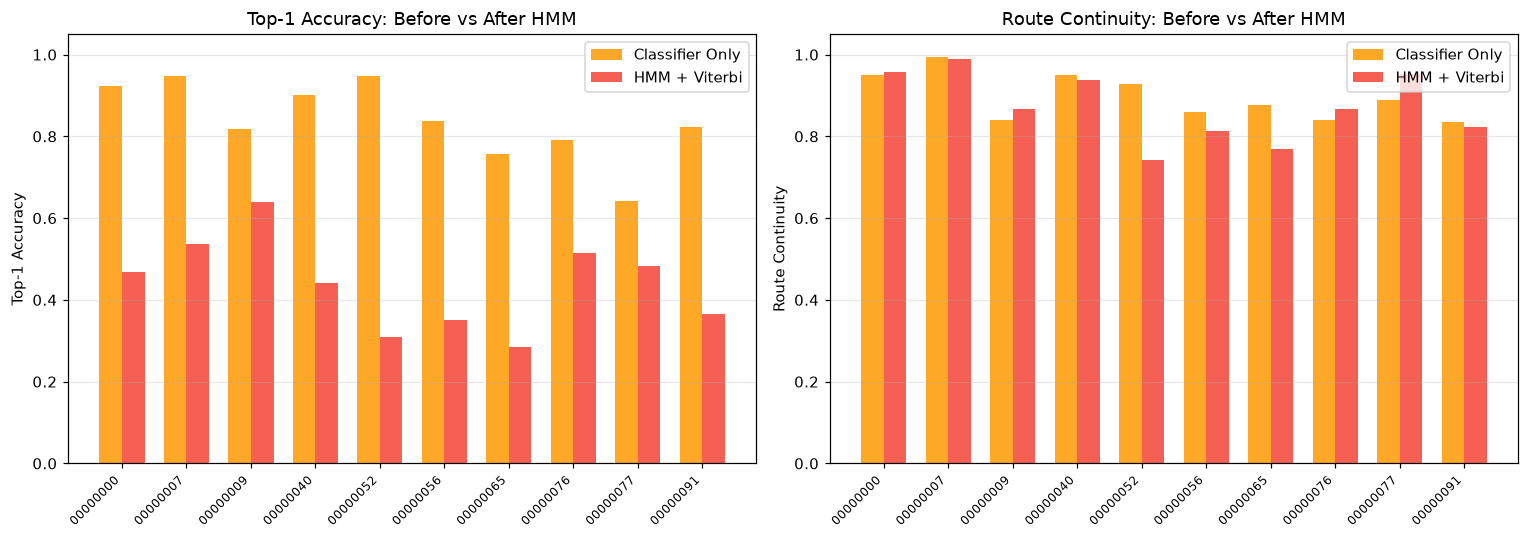


Mean Classifier Top-1 Acc : 0.8387
Mean HMM Viterbi Top-1 Acc: 0.4392
Mean Classifier Continuity : 0.8962
Mean HMM Continuity        : 0.8721


In [14]:
# ── Before vs After summary ─────────────────────────────────────
print('\n━━━ Aggregate Before vs After HMM ━━━')
agg = vit_df[['clf_top1_acc','hmm_top1_acc','clf_continuity','hmm_continuity','acc_delta','cont_delta']].agg(['mean','min','max'])
display(agg.round(4))

# ── Bar chart: Before vs After per trip ────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(vit_df))
w = 0.35

ax = axes[0]
ax.bar(x - w/2, vit_df['clf_top1_acc'],  w, label='Classifier Only', color='#FF9800', alpha=0.85)
ax.bar(x + w/2, vit_df['hmm_top1_acc'],  w, label='HMM + Viterbi',   color='#F44336', alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(vit_df['trip_id'], rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Top-1 Accuracy'); ax.set_title('Top-1 Accuracy: Before vs After HMM')
ax.legend(); ax.grid(axis='y', alpha=0.3); ax.set_ylim(0, 1.05)

ax = axes[1]
ax.bar(x - w/2, vit_df['clf_continuity'], w, label='Classifier Only', color='#FF9800', alpha=0.85)
ax.bar(x + w/2, vit_df['hmm_continuity'], w, label='HMM + Viterbi',   color='#F44336', alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(vit_df['trip_id'], rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Route Continuity'); ax.set_title('Route Continuity: Before vs After HMM')
ax.legend(); ax.grid(axis='y', alpha=0.3); ax.set_ylim(0, 1.05)

plt.tight_layout()
fig.savefig(f'{RESULTS_OUT}/before_vs_after_hmm.png', dpi=120, bbox_inches='tight')
plt.show()

print(f"\nMean Classifier Top-1 Acc : {vit_df['clf_top1_acc'].mean():.4f}")
print(f"Mean HMM Viterbi Top-1 Acc: {vit_df['hmm_top1_acc'].mean():.4f}")
print(f"Mean Classifier Continuity : {vit_df['clf_continuity'].mean():.4f}")
print(f"Mean HMM Continuity        : {vit_df['hmm_continuity'].mean():.4f}")

---
## Section 4 — Phase 6: Folium Interactive Maps (All Student-Test Trips)
4-layer maps: Raw GPS → Road Network → Classifier Route → HMM+Viterbi Route

In [15]:
def arcs_to_coords(arc_seq, arcs_df, nodes_df):
    coords = []; prev = None
    for arc_id in arc_seq:
        arc_id = int(arc_id)
        if arc_id == prev: continue
        u = int(arcs_df['u'].iloc[arc_id])
        coords.append([float(nodes_df['lat'].iloc[u]), float(nodes_df['lon'].iloc[u])])
        prev = arc_id
    if len(arc_seq):
        v = int(arcs_df['v'].iloc[int(arc_seq[-1])])
        coords.append([float(nodes_df['lat'].iloc[v]), float(nodes_df['lon'].iloc[v])])
    return coords


def build_folium_map(trip, clf_arcs=None, hmm_arcs=None, title=''):
    track = trip.track; nodes = trip.nodes; arcs = trip.arcs
    center = [float(track['lat'].mean()), float(track['lon'].mean())]
    m = folium.Map(location=center, zoom_start=15, tiles='CartoDB positron', control_scale=True)

    # Road network
    rg = FeatureGroup(name='⬜ Road Network', show=False)
    step = max(1, len(arcs) // 500)  # sample for performance
    for arc_id in range(0, len(arcs), step):
        u, v = int(arcs['u'].iloc[arc_id]), int(arcs['v'].iloc[arc_id])
        folium.PolyLine([[nodes['lat'].iloc[u], nodes['lon'].iloc[u]],
                          [nodes['lat'].iloc[v], nodes['lon'].iloc[v]]],
                         color='#9E9E9E', weight=1.5, opacity=0.5).add_to(rg)
    rg.add_to(m)

    # Raw GPS
    gg = FeatureGroup(name='🔵 Raw GPS', show=True)
    step_gps = max(1, len(track) // 400)
    for i in range(0, len(track), step_gps):
        folium.CircleMarker([track['lat'].iloc[i], track['lon'].iloc[i]],
            radius=3, color='#2196F3', fill=True, fill_color='#2196F3',
            fill_opacity=0.7, tooltip=f'obs #{i}').add_to(gg)
    gg.add_to(m)

    # Ground truth
    if trip.route is not None:
        gt_coords = arcs_to_coords(trip.route, arcs, nodes)
        gt = FeatureGroup(name='🟢 Ground Truth', show=True)
        folium.PolyLine(gt_coords, color='#4CAF50', weight=5, opacity=0.85,
                         tooltip='Ground Truth').add_to(gt)
        gt.add_to(m)

    # Classifier route
    if clf_arcs is not None:
        clf_coords = arcs_to_coords(clf_arcs, arcs, nodes)
        cg = FeatureGroup(name='🟠 Classifier Route', show=True)
        folium.PolyLine(clf_coords, color='#FF9800', weight=3, opacity=0.8,
                         dash_array='6 4', tooltip='Classifier Only').add_to(cg)
        cg.add_to(m)

    # HMM route
    if hmm_arcs is not None:
        hmm_coords = arcs_to_coords(hmm_arcs, arcs, nodes)
        hg = FeatureGroup(name='🔴 HMM + Viterbi Route', show=True)
        folium.PolyLine(hmm_coords, color='#F44336', weight=4, opacity=0.9,
                         tooltip='HMM + Viterbi').add_to(hg)
        hg.add_to(m)

    LayerControl(collapsed=False).add_to(m)
    legend = f"""
    <div style="position:fixed;bottom:30px;left:30px;z-index:9999;background:white;
                padding:10px 14px;border-radius:8px;box-shadow:0 2px 8px rgba(0,0,0,0.3);
                font-family:sans-serif;font-size:12px;">
        <b>PathSnap — {title}</b><br>
        <span style="color:#9E9E9E;">─</span> Road Network<br>
        <span style="color:#2196F3;">●</span> Raw GPS Observations<br>
        <span style="color:#4CAF50;">━</span> Ground-Truth Route<br>
        <span style="color:#FF9800;">╌</span> Classifier-Only Prediction<br>
        <span style="color:#F44336;">━</span> HMM + Viterbi Prediction<br>
    </div>"""
    m.get_root().html.add_child(folium.Element(legend))
    return m


print('✅ Folium map builder defined')

✅ Folium map builder defined


In [16]:
# ── Generate maps for all student-test trips ───────────────────
os.makedirs(MAPS_OUT, exist_ok=True)
saved_maps = []

for i, trip_id in enumerate(trip_ids):
    trip      = load_trip(f'{EVAL_PARTITION}/{trip_id}', trip_id, load_route=True)
    projector = LocalMetricProjector(trip.track['lon'].mean(), trip.track['lat'].mean())

    # Classifier predictions
    feat_df, _ = extract_features_for_trip(trip, k_candidates=8, is_training=False)
    X = feat_df[FEATURE_COLUMNS].values
    probs = active_model.predict_proba(X)[:, 1]
    feat_df['pred_score'] = probs
    clf_arcs = (feat_df.sort_values(['obs_idx', 'pred_score'], ascending=[True, False])
                .groupby('obs_idx')['arc_id'].first().values)

    # Viterbi (re-use from evaluation above)
    row = vit_df[vit_df['trip_id'] == trip_id]
    try:
        hmm_arcs = viterbi_decode_trip(trip, active_model)
    except Exception:
        hmm_arcs = clf_arcs

    # Build + save map
    m = build_folium_map(trip, clf_arcs, hmm_arcs, title=f'Trip {trip_id}')
    out_path = os.path.join(MAPS_OUT, f'trip_{trip_id}_map.html')
    m.save(out_path)
    saved_maps.append((trip_id, out_path))
    print(f'  [{i+1}/{len(trip_ids)}] Saved {out_path}')

print(f'\n✅ Generated {len(saved_maps)} interactive maps in {MAPS_OUT}/')

  [1/10] Saved ../artifacts/plots/folium_maps/trip_00000000_map.html
  [2/10] Saved ../artifacts/plots/folium_maps/trip_00000007_map.html
  [3/10] Saved ../artifacts/plots/folium_maps/trip_00000009_map.html
  [4/10] Saved ../artifacts/plots/folium_maps/trip_00000040_map.html
  [5/10] Saved ../artifacts/plots/folium_maps/trip_00000052_map.html
  [6/10] Saved ../artifacts/plots/folium_maps/trip_00000056_map.html
  [7/10] Saved ../artifacts/plots/folium_maps/trip_00000065_map.html
  [8/10] Saved ../artifacts/plots/folium_maps/trip_00000076_map.html
  [9/10] Saved ../artifacts/plots/folium_maps/trip_00000077_map.html
  [10/10] Saved ../artifacts/plots/folium_maps/trip_00000091_map.html

✅ Generated 10 interactive maps in ../artifacts/plots/folium_maps/


In [17]:
# ── Display first map inline ───────────────────────────────────
first_trip_id, first_map_path = saved_maps[0]
print(f'Displaying inline map for Trip {first_trip_id}:')
display(IFrame(first_map_path, width='100%', height=520))

Displaying inline map for Trip 00000000:


In [18]:
# ── Clickable links to all maps ────────────────────────────────
print('All generated maps:')
links_html = '<ul>'
for trip_id, path in saved_maps:
    abs_path = os.path.abspath(path)
    links_html += f'<li><a href="file://{abs_path}" target="_blank">Trip {trip_id}</a></li>'
    print(f'  Trip {trip_id}: file://{abs_path}')
links_html += '</ul>'
display(HTML(f'<h4>Open Maps:</h4>{links_html}'))

All generated maps:
  Trip 00000000: file:///run/media/cow/D/college/sem5/ml/mlhack/artifacts/plots/folium_maps/trip_00000000_map.html
  Trip 00000007: file:///run/media/cow/D/college/sem5/ml/mlhack/artifacts/plots/folium_maps/trip_00000007_map.html
  Trip 00000009: file:///run/media/cow/D/college/sem5/ml/mlhack/artifacts/plots/folium_maps/trip_00000009_map.html
  Trip 00000040: file:///run/media/cow/D/college/sem5/ml/mlhack/artifacts/plots/folium_maps/trip_00000040_map.html
  Trip 00000052: file:///run/media/cow/D/college/sem5/ml/mlhack/artifacts/plots/folium_maps/trip_00000052_map.html
  Trip 00000056: file:///run/media/cow/D/college/sem5/ml/mlhack/artifacts/plots/folium_maps/trip_00000056_map.html
  Trip 00000065: file:///run/media/cow/D/college/sem5/ml/mlhack/artifacts/plots/folium_maps/trip_00000065_map.html
  Trip 00000076: file:///run/media/cow/D/college/sem5/ml/mlhack/artifacts/plots/folium_maps/trip_00000076_map.html
  Trip 00000077: file:///run/media/cow/D/college/sem5/ml/mlh

---
## ✅ Phase 2 Summary

| Phase | Component | Output |
|---|---|---|
| 4 — Bayesian Opt | Optuna 50-trial TPE on HGB | `artifacts/bayesian_opt/` |
| 4 — Tuned Model | HistGradientBoosting_tuned.joblib | `artifacts/models/` |
| 5 — HMM/Viterbi | Before vs After comparison | `artifacts/results/viterbi_evaluation.csv` |
| 6 — Folium Maps | 10 interactive HTML maps | `artifacts/plots/folium_maps/` |

### Next: Start the FastAPI server + Streamlit UI
```bash
# Laptop 1 (this machine):
uvicorn Phase_2.backend.app:app --host 0.0.0.0 --port 8000

# Laptop 2 (Windows Lenovo):
streamlit run Phase_2/frontend/app.py
```